Домашнее задание
Когда-нибудь это закончится? Симуляция распространения болезни. Работа с NetworkX

Цель:
Перед вами не совсем стандартное домашнее задание, так как в нём практически не будет машинного обучения (если не считать анализа графов), но будет довольно много аналитики, симуляций, визуализаций и очень интересных выводов. Так как не совсем про ML, то и выполнять это задание не обязательно для успешного завершения курса. Но если вам интересно узнать, как можно смоделировать распространение инфекции по международной сети аэропортов, увидеть, как заражение аэропортов-хабов приводит к взрывному росту заболеваний и создать свой локальный Plague Inc., то давайте приступать :)


Описание/Пошаговая инструкция выполнения домашнего задания:
Набор данных представляет собой основные маршруты авиаперелетов в США за один месяц 2008-го года. В качестве модели распространения инфекции предлагается использовать SI (susceptible-infected) модель, в которой каждый аэропорт имеет два возможных состояния - “здоровый” или “зараженный”. Здоровый аэропорт может заразиться с некоторой вероятностью p (infection probability), если к нему прилетает самолет из зараженного города. Инфекция начинает распространение из некоторого стартового аэропорта и заканчивает распространение, когда все перелеты из датасета завершены.


Часть 1. Пишем симуляцию.

Напишите функцию для симуляции одного прохода по всему датасету и распространения инфекции. Функция должна принимать на вход стартовый город, в котором изначально началась инфекция и вероятность распространения инфекции p. На выходе функция должна возвращать словарь, в котором ключом будет время заражения аэропорта, значением - название аэропорта. В теле функции вам нужно написать проход по всему датасету (имеет смысл использовать itertuples), где вы будете проверять, является ли текущий рейс “заразным” и если да - с вероятностью p заражать новый аэропорт.
В качестве стартовой ноды/аэропорта для симуляций можно использовать Allentown (node_id = 0).

Часть 2. Как инфекционность (вероятность заражения) болезни влияет на скорость распространения?

Давайте посмотрим, насколько заразной должна быть болезнь, чтобы заразить все аэропорты в сети. Для каждой из вероятностей p=[0.01, 0.05, 0.1, 0.5, 1.] прогоните по 10 симуляций распространения, каждый раз сохраняя результаты.
Для каждых 12 часов симуляции посчитайте, какой средний процент аэропортов от общего их числа, был заражен к этому моменту времени. Постройте графики числа зараженных городов в зависимости от времени для каждой из вероятностей.

Часть 3. Может ли информация о сети помочь предсказать, кто будет заражен?

Настало время поработать с NetworkX. По имеющемуся датасету вам нужно построить ненаправленный граф всех аэропортов, используя относительное число перелетов между соседними аэропортами в качестве веса ребра. Например, если из аэропорта А в аэропорт Б суммарно есть 5 рейсов, из Б в А 10 рейсов, а всего в сети 150 перелетов, то вес ребра между А и Б должен быть равен (5+10)/150 = 0.1.
Прогоните вашу симуляцию 50 раз, используя p=0.5 и стартовый аэропорт Allentown, каждый раз сохраняя результаты. Используя данные симуляций посчитайте медианное время до заражения каждого города.
Теперь используя построенный вами граф, для каждого города посчитайте его коэффициент кластеризации (nx.clustering), степень (nx.degree) и центральность (nx.betweenness_centrality).
Наконец, постройте scatter-plot-ы для медианного времени заражения и каждой из рассчитанных выше метрик. Также посчитайте коэффициент корреляции Спирмана между этими показателями и попробуйте проинтерпретировать полученные результаты. Какая из метрик графа сильнее всего скоррелирована со временем заражения? Почему?

In [96]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
import math
import networkx as nx
import random

random.seed = 42

In [97]:
df = pd.read_csv('2008.csv')

In [98]:
df.head()

,Year,Month,DayofMonth,DayOfWeek,DepTime,CRSDepTime,ArrTime,CRSArrTime,UniqueCarrier,FlightNum,...,TaxiIn,TaxiOut,Cancelled,CancellationCode,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,2008,1,3,4,2003.0,1955,2211.0,2225,WN,335,...,4.0,8.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN
1,2008,1,3,4,754.0,735,1002.0,1000,WN,3231,...,5.0,10.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN
2,2008,1,3,4,628.0,620,804.0,750,WN,448,...,3.0,17.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN
3,2008,1,3,4,926.0,930,1054.0,1100,WN,1746,...,3.0,7.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN
4,2008,1,3,4,1829.0,1755,1959.0,1925,WN,3920,...,3.0,10.0,0,NaN,0,2.0,0.0,0.0,0.0,32.0


In [99]:
df.describe()

,Year,Month,DayofMonth,DayOfWeek,DepTime,CRSDepTime,ArrTime,CRSArrTime,FlightNum,ActualElapsedTime,...,Distance,TaxiIn,TaxiOut,Cancelled,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
count,7009728.0,7.009728e+06,7.009728e+06,7.009728e+06,6.873482e+06,7.009728e+06,6.858079e+06,7.009728e+06,7.009728e+06,6.855029e+06,...,7.009728e+06,6.858079e+06,6.872670e+06,7.009728e+06,7.009728e+06,1.524735e+06,1.524735e+06,1.524735e+06,1.524735e+06,1.524735e+06
mean,2008.0,6.375130e+00,1.572801e+01,3.924182e+00,1.333830e+03,1.326086e+03,1.481258e+03,1.494801e+03,2.224200e+03,1.273224e+02,...,7.263870e+02,6.860852e+00,1.645305e+01,1.960618e-02,2.463006e-03,1.577206e+01,3.039031e+00,1.716462e+01,7.497434e-02,2.077098e+01
std,0.0,3.406737e+00,8.797068e+00,1.988259e+00,4.780689e+02,4.642509e+02,5.052251e+02,4.826728e+02,1.961716e+03,7.018731e+01,...,5.621018e+02,4.933649e+00,1.133280e+01,1.386426e-01,4.956753e-02,4.009912e+01,1.950287e+01,3.189495e+01,1.837940e+00,3.925964e+01
min,2008.0,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.200000e+01,...,1.100000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2008.0,3.000000e+00,8.000000e+00,2.000000e+00,9.280000e+02,9.250000e+02,1.107000e+03,1.115000e+03,6.220000e+02,7.700000e+01,...,3.250000e+02,4.000000e+00,1.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2008.0,6.000000e+00,1.600000e+01,4.000000e+00,1.325000e+03,1.320000e+03,1.512000e+03,1.517000e+03,1.571000e+03,1.100000e+02,...,5.810000e+02,6.000000e+00,1.400000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,6.000000e+00,0.000000e+00,0.000000e+00
75%,2008.0,9.000000e+00,2.300000e+01,6.000000e+00,1.728000e+03,1.715000e+03,1.909000e+03,1.907000e+03,3.518000e+03,1.570000e+02,...,9.540000e+02,8.000000e+00,1.900000e+01,0.000000e+00,0.000000e+00,1.600000e+01,0.000000e+00,2.100000e+01,0.000000e+00,2.600000e+01
max,2008.0,1.200000e+01,3.100000e+01,7.000000e+00,2.400000e+03,2.359000e+03,2.400000e+03,2.400000e+03,9.743000e+03,1.379000e+03,...,4.962000e+03,3.080000e+02,4.290000e+02,1.000000e+00,1.000000e+00,2.436000e+03,1.352000e+03,1.357000e+03,3.920000e+02,1.316000e+03


In [100]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7009728 entries, 0 to 7009727
Data columns (total 29 columns):
 #   Column             Dtype  
---  ------             -----  
 0   Year               int64  
 1   Month              int64  
 2   DayofMonth         int64  
 3   DayOfWeek          int64  
 4   DepTime            float64
 5   CRSDepTime         int64  
 6   ArrTime            float64
 7   CRSArrTime         int64  
 8   UniqueCarrier      object 
 9   FlightNum          int64  
 10  TailNum            object 
 11  ActualElapsedTime  float64
 12  CRSElapsedTime     float64
 13  AirTime            float64
 14  ArrDelay           float64
 15  DepDelay           float64
 16  Origin             object 
 17  Dest               object 
 18  Distance           int64  
 19  TaxiIn             float64
 20  TaxiOut            float64
 21  Cancelled          int64  
 22  CancellationCode   object 
 23  Diverted           int64  
 24  CarrierDelay       float64
 25  WeatherDelay      

In [101]:
df.nunique()

Year                    1
Month                  12
DayofMonth             31
DayOfWeek               7
DepTime              1440
CRSDepTime           1217
ArrTime              1440
CRSArrTime           1378
UniqueCarrier          20
FlightNum            7539
TailNum              5373
ActualElapsedTime     689
CRSElapsedTime        525
AirTime               663
ArrDelay             1153
DepDelay             1134
Origin                303
Dest                  304
Distance             1435
TaxiIn                190
TaxiOut               342
Cancelled               2
CancellationCode        4
Diverted                2
CarrierDelay          984
WeatherDelay          599
NASDelay              574
SecurityDelay         156
LateAircraftDelay     564
dtype: int64

In [102]:
df.isnull().sum()

Year                       0
Month                      0
DayofMonth                 0
DayOfWeek                  0
DepTime               136246
CRSDepTime                 0
ArrTime               151649
CRSArrTime                 0
UniqueCarrier              0
FlightNum                  0
TailNum                83365
ActualElapsedTime     154699
CRSElapsedTime           844
AirTime               154699
ArrDelay              154699
DepDelay              136246
Origin                     0
Dest                       0
Distance                   0
TaxiIn                151649
TaxiOut               137058
Cancelled                  0
CancellationCode     6872294
Diverted                   0
CarrierDelay         5484993
WeatherDelay         5484993
NASDelay             5484993
SecurityDelay        5484993
LateAircraftDelay    5484993
dtype: int64

In [103]:
# Отфильтруем отмененные рейсы
data = df[(df['Cancelled']==0)&(df['Diverted']==0)]

Нужно унифицировать время всех аэропортов, находящихся в разных часовых поясах

In [104]:
# Загружаем данные об аэропортах и их часовых поясах
tz = pd.read_csv('airports_and_timezones.csv')
tz.head()

,iata,airport,city,state,latitude,longitude,timezone,gmt_offset
0,ABQ,Albuquerque International,Albuquerque,NM,35.040222,-106.609194,Mountain Standard Time (MST),-7
1,ANC,Ted Stevens Anchorage International,Anchorage,AK,61.174320,-149.996186,Alaska Standard Time (AKST),-9
2,ATL,William B Hartsfield-Atlanta Intl,Atlanta,GA,33.640444,-84.426944,Eastern Standard Time (EST),-5
3,AUS,Austin-Bergstrom International,Austin,TX,30.194533,-97.669872,Central Standard Time (CST),-6
4,BDL,Bradley International,Windsor Locks,CT,41.938874,-72.683228,Eastern Standard Time (EST),-5


In [105]:
# Добавляем значение GMT offset к основной таблице
tz.rename(columns={'iata': 'Origin'}, inplace=True)
data = pd.merge(data, tz[['Origin','gmt_offset']], on="Origin", how="left")
data.head()

,Year,Month,DayofMonth,DayOfWeek,DepTime,CRSDepTime,ArrTime,CRSArrTime,UniqueCarrier,FlightNum,...,TaxiOut,Cancelled,CancellationCode,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay,gmt_offset
0,2008,1,3,4,2003.0,1955,2211.0,2225,WN,335,...,8.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN,-5
1,2008,1,3,4,754.0,735,1002.0,1000,WN,3231,...,10.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN,-5
2,2008,1,3,4,628.0,620,804.0,750,WN,448,...,17.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN,-5
3,2008,1,3,4,926.0,930,1054.0,1100,WN,1746,...,7.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN,-5
4,2008,1,3,4,1829.0,1755,1959.0,1925,WN,3920,...,10.0,0,NaN,0,2.0,0.0,0.0,0.0,32.0,-5


In [106]:
min_gmt = data.gmt_offset.min()
min_gmt

np.int64(-10)

In [107]:
data.isnull().sum() 

Year                       0
Month                      0
DayofMonth                 0
DayOfWeek                  0
DepTime                    0
CRSDepTime                 0
ArrTime                    0
CRSArrTime                 0
UniqueCarrier              0
FlightNum                  0
TailNum                    5
ActualElapsedTime          0
CRSElapsedTime             0
AirTime                    0
ArrDelay                   0
DepDelay                   0
Origin                     0
Dest                       0
Distance                   0
TaxiIn                     0
TaxiOut                    0
Cancelled                  0
CancellationCode     6855029
Diverted                   0
CarrierDelay         5330294
WeatherDelay         5330294
NASDelay             5330294
SecurityDelay        5330294
LateAircraftDelay    5330294
gmt_offset                 0
dtype: int64

В данных уже нет отсутствующих значений DepDelay (задержка отправления) и ActualElapsedTime (фактическое прошедшее время от отправления до прибытия в минутах) 

Вычислим столбцы значений времени отправления и времени прибытия, выравненные по региону с gmt_offset = min_gmt (Гавайи)

In [108]:
data['DepDateTime'] = pd.to_datetime(dict(year=data.Year, month=data.Month, day=data.DayofMonth, hour=data.CRSDepTime//100+data.gmt_offset-min_gmt, minute=data.CRSDepTime%100 + data.DepDelay)) 

In [109]:
data['ArrDateTime'] = data['DepDateTime'] + data['ActualElapsedTime'].astype('timedelta64[m]')

Будем работать с записями отсортированными по времени прибытия самолета в аэропорт

In [110]:
data = data[['Origin', 'Dest', 'DepDateTime', 'ArrDateTime']]
data = data.sort_values(by='ArrDateTime').reset_index(drop=True)

In [111]:
data

,Origin,Dest,DepDateTime,ArrDateTime
0,LAS,DFW,2008-01-01 02:35:00,2008-01-01 04:51:00
1,ANC,SEA,2008-01-01 01:26:00,2008-01-01 05:08:00
2,ANC,SEA,2008-01-01 01:51:00,2008-01-01 05:21:00
3,HNL,LIH,2008-01-01 04:53:00,2008-01-01 05:28:00
4,LAX,DFW,2008-01-01 02:38:00,2008-01-01 05:29:00
...,...,...,...,...
6855024,IAD,LAX,2009-01-01 04:30:00,2009-01-01 10:13:00
6855025,JFK,PSE,2009-01-01 06:48:00,2009-01-01 10:36:00
6855026,SEA,DFW,2009-01-01 08:29:00,2009-01-01 11:47:00
6855027,SNA,DFW,2009-01-01 10:26:00,2009-01-01 13:14:00


In [112]:
data[data['DepDateTime'] < data['ArrDateTime']].count()

Origin         6855029
Dest           6855029
DepDateTime    6855029
ArrDateTime    6855029
dtype: int64

### Часть 1. Пишем симуляцию.

Напишите функцию для симуляции одного прохода по всему датасету и распространения инфекции. Функция должна принимать на вход стартовый город, в котором изначально началась инфекция и вероятность распространения инфекции p. На выходе функция должна возвращать словарь, в котором ключом будет время заражения аэропорта, значением - название аэропорта. В теле функции вам нужно написать проход по всему датасету (имеет смысл использовать itertuples), где вы будете проверять, является ли текущий рейс “заразным” и если да - с вероятностью p заражать новый аэропорт.
В качестве стартовой ноды/аэропорта для симуляций можно использовать Allentown (node_id = 0).

In [113]:
def virus_simulation(p, start='ABE'):

    infected = dict()
    infected[start] = pd.Timestamp('2008-01-01 00:00:00') 

    for row in data.itertuples():
        if (row.Dest not in infected.keys()) and (row.Origin in infected.keys()) and (row.DepDateTime > infected[row.Origin]):
                    rand = random.random()
                    if p > rand:
                        infected[row.Dest] = row.ArrDateTime
    
    return infected

In [114]:
# Тест
vs = virus_simulation(1)
vs

{'ABE': Timestamp('2008-01-01 00:00:00'),
 'DTW': Timestamp('2008-01-01 13:06:00'),
 'PIT': Timestamp('2008-01-01 14:45:00'),
 'ELM': Timestamp('2008-01-01 14:47:00'),
 'CMH': Timestamp('2008-01-01 14:53:00'),
 'ORD': Timestamp('2008-01-01 15:17:00'),
 'LEX': Timestamp('2008-01-01 15:22:00'),
 'DCA': Timestamp('2008-01-01 15:27:00'),
 'CLT': Timestamp('2008-01-01 15:32:00'),
 'MSN': Timestamp('2008-01-01 15:51:00'),
 'HSV': Timestamp('2008-01-01 15:52:00'),
 'IND': Timestamp('2008-01-01 15:52:00'),
 'SDF': Timestamp('2008-01-01 15:58:00'),
 'MDW': Timestamp('2008-01-01 16:04:00'),
 'MKE': Timestamp('2008-01-01 16:13:00'),
 'JFK': Timestamp('2008-01-01 16:20:00'),
 'BNA': Timestamp('2008-01-01 16:21:00'),
 'EWR': Timestamp('2008-01-01 16:31:00'),
 'LGA': Timestamp('2008-01-01 16:34:00'),
 'MSP': Timestamp('2008-01-01 16:36:00'),
 'BOS': Timestamp('2008-01-01 16:37:00'),
 'RST': Timestamp('2008-01-01 16:39:00'),
 'PVD': Timestamp('2008-01-01 16:40:00'),
 'PHL': Timestamp('2008-01-01 16:4

### Часть 2. Как инфекционность (вероятность заражения) болезни влияет на скорость распространения?

Давайте посмотрим, насколько заразной должна быть болезнь, чтобы заразить все аэропорты в сети. Для каждой из вероятностей p=[0.01, 0.05, 0.1, 0.5, 1.] прогоните по 10 симуляций распространения, каждый раз сохраняя результаты.
Для каждых 12 часов симуляции посчитайте, какой средний процент аэропортов от общего их числа, был заражен к этому моменту времени. Постройте графики числа зараженных городов в зависимости от времени для каждой из вероятностей.

In [115]:
probabilities = {'p=0.01':0.01, 'p=0.05':0.05, 'p=0.1':0.1, 'p=0.5':0.5, 'p=1':1.}
n = 10
vs_res = dict()
for p_name, p in probabilities.items():
    for i in range(n):
        vs = virus_simulation(p)
        if p_name in vs_res.keys():
            vs_res[p_name] = vs_res[p_name]+list(vs.values())
        else:
            vs_res[p_name] = list(vs.values())

In [116]:
vs_res

{'p=0.01': [Timestamp('2008-01-01 00:00:00'),
  Timestamp('2008-01-11 23:49:00'),
  Timestamp('2008-01-12 05:55:00'),
  Timestamp('2008-01-12 15:14:00'),
  Timestamp('2008-01-12 18:04:00'),
  Timestamp('2008-01-12 19:36:00'),
  Timestamp('2008-01-12 19:39:00'),
  Timestamp('2008-01-12 20:03:00'),
  Timestamp('2008-01-12 20:17:00'),
  Timestamp('2008-01-12 20:23:00'),
  Timestamp('2008-01-12 22:20:00'),
  Timestamp('2008-01-12 22:30:00'),
  Timestamp('2008-01-13 00:04:00'),
  Timestamp('2008-01-13 00:10:00'),
  Timestamp('2008-01-13 01:09:00'),
  Timestamp('2008-01-13 01:40:00'),
  Timestamp('2008-01-13 02:24:00'),
  Timestamp('2008-01-13 11:11:00'),
  Timestamp('2008-01-13 11:44:00'),
  Timestamp('2008-01-13 12:19:00'),
  Timestamp('2008-01-13 12:29:00'),
  Timestamp('2008-01-13 12:46:00'),
  Timestamp('2008-01-13 15:13:00'),
  Timestamp('2008-01-13 15:51:00'),
  Timestamp('2008-01-13 16:51:00'),
  Timestamp('2008-01-13 17:24:00'),
  Timestamp('2008-01-13 17:54:00'),
  Timestamp('2008-

In [117]:
# Получаем датафрейм из структуры данных симуляций
vsdf = pd.DataFrame()
for p_name, date_list in vs_res.items():
    dic = dict()
    dic[p_name] = date_list
    vsdf = pd.concat([vsdf, pd.DataFrame(dic).melt(value_vars=[p_name], var_name='probability', value_name='original_time')])

vsdf

,probability,original_time
0,p=0.01,2008-01-01 00:00:00
1,p=0.01,2008-01-11 23:49:00
2,p=0.01,2008-01-12 05:55:00
3,p=0.01,2008-01-12 15:14:00
4,p=0.01,2008-01-12 18:04:00
...,...,...
3015,p=1,2008-07-07 14:29:00
3016,p=1,2008-07-07 15:25:00
3017,p=1,2008-08-20 04:41:00
3018,p=1,2008-10-01 16:08:00


In [118]:
#Добавляем столбец с округленным до 12 часов временем, его используем на графике
vsdf['time'] = vsdf['original_time'].dt.round(freq='12h')
vsdf

,probability,original_time,time
0,p=0.01,2008-01-01 00:00:00,2008-01-01 00:00:00
1,p=0.01,2008-01-11 23:49:00,2008-01-12 00:00:00
2,p=0.01,2008-01-12 05:55:00,2008-01-12 00:00:00
3,p=0.01,2008-01-12 15:14:00,2008-01-12 12:00:00
4,p=0.01,2008-01-12 18:04:00,2008-01-13 00:00:00
...,...,...,...
3015,p=1,2008-07-07 14:29:00,2008-07-07 12:00:00
3016,p=1,2008-07-07 15:25:00,2008-07-07 12:00:00
3017,p=1,2008-08-20 04:41:00,2008-08-20 00:00:00
3018,p=1,2008-10-01 16:08:00,2008-10-01 12:00:00


Строим график процента зараженных городов

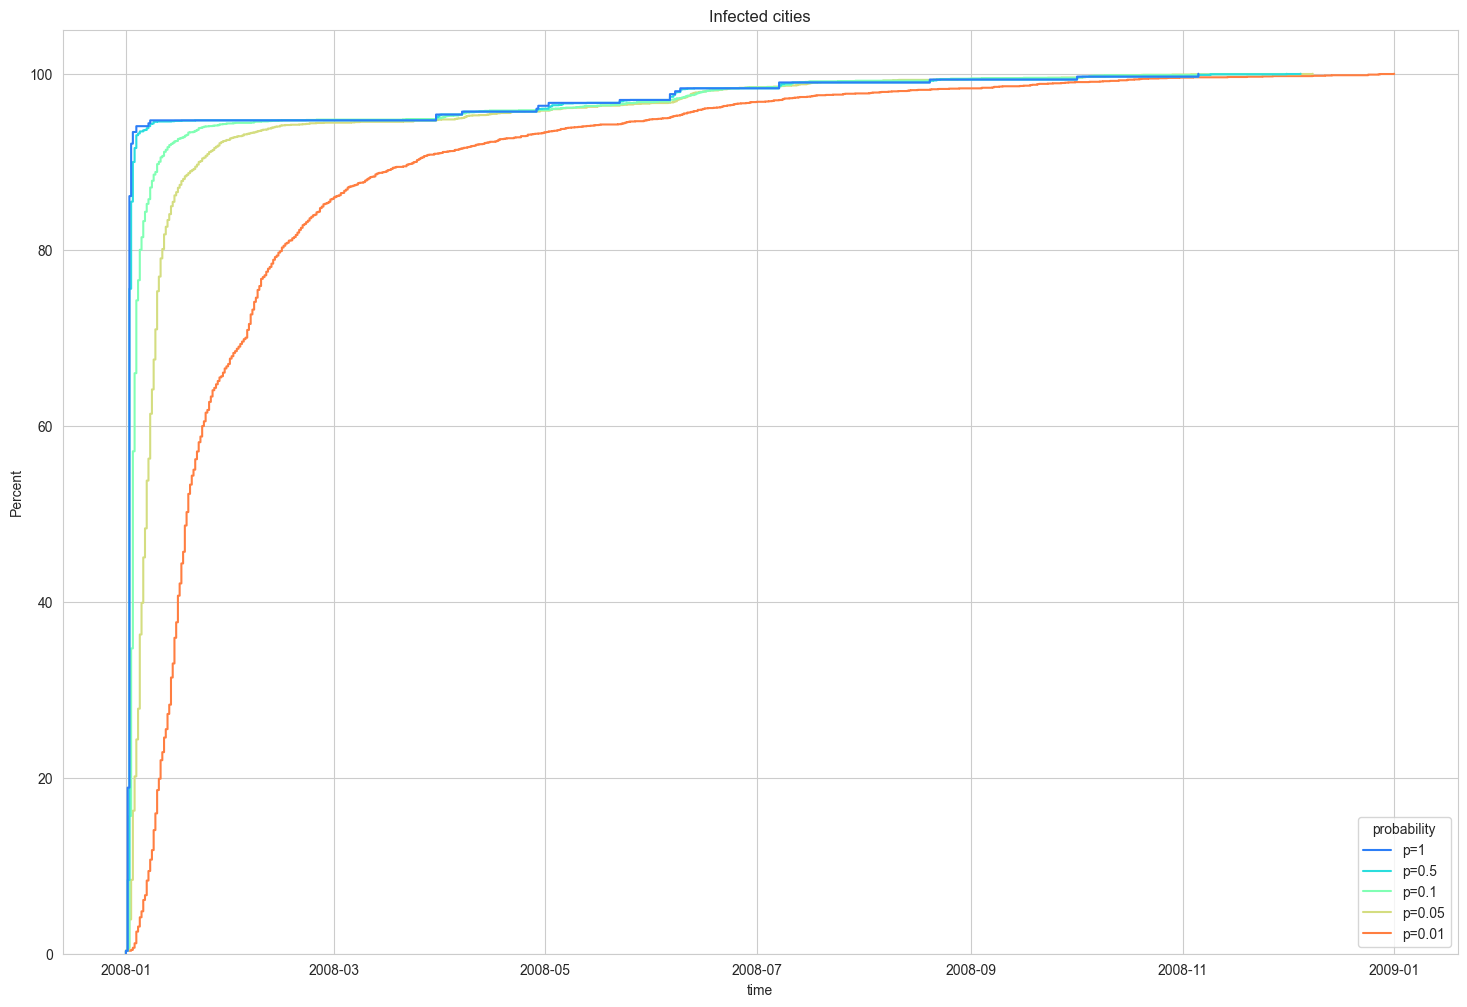

In [119]:
sns.set_style("whitegrid")
plt.figure(figsize = (18,12))
sns.ecdfplot(data=vsdf, x='time', hue='probability', hue_order=['p=1', 'p=0.5', 'p=0.1', 'p=0.05', 'p=0.01'], palette='rainbow', stat='percent').set_title('Infected cities')
plt.show()

График с логарифмической шкалой

In [120]:
vsdf['hours'] = (vsdf['time'] - vsdf['time'].min()).astype('timedelta64[s]').astype('int')//3600
vsdf

,probability,original_time,time,hours
0,p=0.01,2008-01-01 00:00:00,2008-01-01 00:00:00,0
1,p=0.01,2008-01-11 23:49:00,2008-01-12 00:00:00,264
2,p=0.01,2008-01-12 05:55:00,2008-01-12 00:00:00,264
3,p=0.01,2008-01-12 15:14:00,2008-01-12 12:00:00,276
4,p=0.01,2008-01-12 18:04:00,2008-01-13 00:00:00,288
...,...,...,...,...
3015,p=1,2008-07-07 14:29:00,2008-07-07 12:00:00,4524
3016,p=1,2008-07-07 15:25:00,2008-07-07 12:00:00,4524
3017,p=1,2008-08-20 04:41:00,2008-08-20 00:00:00,5568
3018,p=1,2008-10-01 16:08:00,2008-10-01 12:00:00,6588


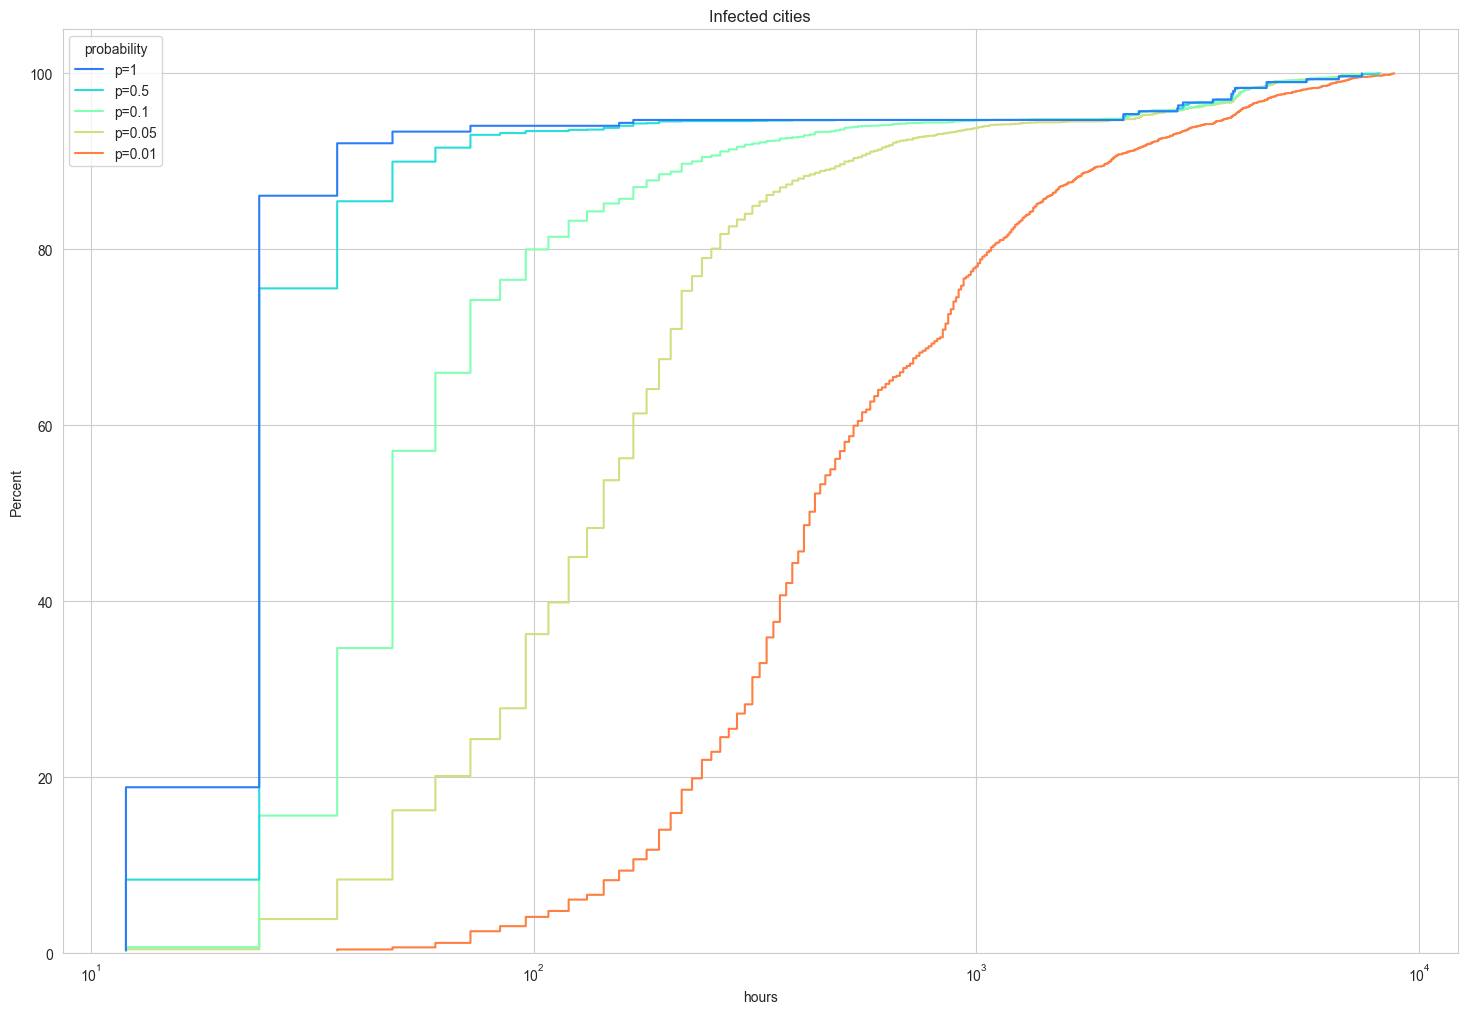

In [121]:
sns.set_style("whitegrid")
plt.figure(figsize = (18,12))
sns.ecdfplot(data=vsdf, x='hours', hue='probability', hue_order=['p=1', 'p=0.5', 'p=0.1', 'p=0.05', 'p=0.01'], palette='rainbow', stat='percent',log_scale=(True,False)).set_title('Infected cities')
plt.show()

### Часть 3. Может ли информация о сети помочь предсказать, кто будет заражен?

Настало время поработать с NetworkX. По имеющемуся датасету вам нужно построить ненаправленный граф всех аэропортов, используя относительное число перелетов между соседними аэропортами в качестве веса ребра. Например, если из аэропорта А в аэропорт Б суммарно есть 5 рейсов, из Б в А 10 рейсов, а всего в сети 150 перелетов, то вес ребра между А и Б должен быть равен (5+10)/150 = 0.1.
Прогоните вашу симуляцию 50 раз, используя p=0.5 и стартовый аэропорт Allentown, каждый раз сохраняя результаты. Используя данные симуляций посчитайте медианное время до заражения каждого города.

In [122]:
gr = nx.from_pandas_edgelist(data, source = 'Origin', target = 'Dest')

In [123]:
route_counts = data.groupby(['Origin','Dest']).size().reset_index(name='counts')
route_counts

,Origin,Dest,counts
0,ABE,ATL,835
1,ABE,BHM,1
2,ABE,CLE,791
3,ABE,CLT,457
4,ABE,CVG,243
...,...,...,...
5195,YUM,IPL,323
5196,YUM,LAS,95
5197,YUM,LAX,1037
5198,YUM,PHX,1887


In [124]:
route_number = route_counts.counts.sum()

for row in route_counts.itertuples():
    gr[row.Origin][row.Dest]['weight'] = 0.

for row in route_counts.itertuples():
    gr[row.Origin][row.Dest]['weight'] += 1.*row.counts/route_number

<Axes: ylabel='Count'>

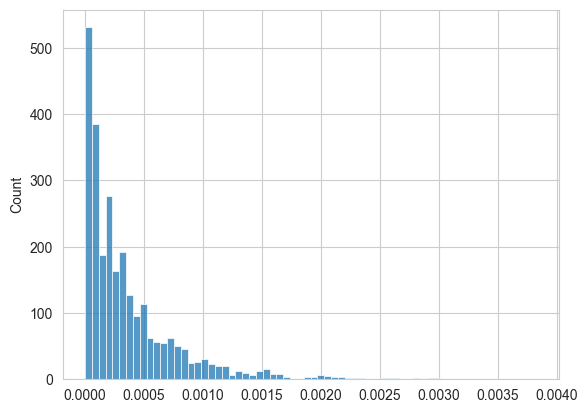

In [125]:
lst = []
for u,v in gr.edges:
    lst.append(gr[u][v]['weight'])

sns.histplot(data=lst)

In [126]:
nx.is_weighted(gr)

True

In [127]:
nodes_res = dict()

for i in range(50):
    vs = virus_simulation(0.5)
    for city in vs.keys():
        time_list = []
        if city in nodes_res.keys():
            nodes_res[city].append(vs[city])
        else: 
            time_list.append(vs[city])
            nodes_res[city] = time_list

In [128]:
city_median_times = dict()

for city in nodes_res.keys():
    city_median_times[city] = pd.Series(nodes_res[city]).median()
    

In [129]:
city_median_times

{'ABE': Timestamp('2008-01-01 00:00:00'),
 'DTW': Timestamp('2008-01-01 13:06:00'),
 'PIT': Timestamp('2008-01-01 17:36:00'),
 'ORD': Timestamp('2008-01-01 15:17:00'),
 'LEX': Timestamp('2008-01-01 18:06:00'),
 'DCA': Timestamp('2008-01-01 17:56:00'),
 'CLT': Timestamp('2008-01-01 16:01:00'),
 'MSN': Timestamp('2008-01-01 17:26:00'),
 'HSV': Timestamp('2008-01-01 18:51:00'),
 'IND': Timestamp('2008-01-01 16:42:00'),
 'SDF': Timestamp('2008-01-01 17:44:30'),
 'BNA': Timestamp('2008-01-01 18:13:00'),
 'LGA': Timestamp('2008-01-01 17:17:00'),
 'RST': Timestamp('2008-01-01 19:43:00'),
 'PVD': Timestamp('2008-01-01 19:28:00'),
 'ATL': Timestamp('2008-01-01 17:52:00'),
 'JFK': Timestamp('2008-01-01 17:50:00'),
 'MSP': Timestamp('2008-01-01 17:09:00'),
 'DFW': Timestamp('2008-01-01 18:18:00'),
 'ROA': Timestamp('2008-01-01 19:28:00'),
 'BOS': Timestamp('2008-01-01 18:10:00'),
 'BWI': Timestamp('2008-01-01 17:32:00'),
 'EWR': Timestamp('2008-01-01 17:38:00'),
 'PHL': Timestamp('2008-01-01 17:2

Теперь используя построенный вами граф, для каждого города посчитайте его коэффициент кластеризации (nx.clustering), степень (nx.degree) и центральность (nx.betweenness_centrality).
Наконец, постройте scatter-plot-ы для медианного времени заражения и каждой из рассчитанных выше метрик. Также посчитайте коэффициент корреляции Спирмана между этими показателями и попробуйте проинтерпретировать полученные результаты. Какая из метрик графа сильнее всего скоррелирована со временем заражения? Почему?

In [130]:
clustering = nx.clustering(gr)
clustering

{'LAS': 0.37045177045177047,
 'DFW': 0.20132420603748177,
 'ANC': 0.3374384236453202,
 'SEA': 0.5324675324675324,
 'HNL': 0.7681159420289855,
 'LIH': 1.0,
 'LAX': 0.3388661899897855,
 'IAH': 0.25710293432696785,
 'OGG': 0.7843137254901961,
 'PDX': 0.5539112050739958,
 'KOA': 0.8333333333333334,
 'SMF': 0.5915915915915916,
 'MSP': 0.21193650793650792,
 'SFO': 0.34824016563147,
 'ITO': 1.0,
 'FAI': 0.6,
 'DEN': 0.23140495867768596,
 'ATL': 0.13899717703992473,
 'DTW': 0.23629112662013957,
 'CVG': 0.25695322376738305,
 'ORD': 0.17825503355704697,
 'PHX': 0.3709508881922675,
 'JFK': 0.41784037558685444,
 'ONT': 0.6515151515151515,
 'SLC': 0.21474201474201474,
 'MCO': 0.3667915106117353,
 'SJU': 0.924901185770751,
 'OXR': 0,
 'FAT': 0.8636363636363636,
 'PSP': 1.0,
 'CIC': 0,
 'SBA': 0.803030303030303,
 'SBP': 0.9523809523809523,
 'ADQ': 0,
 'SMX': 0,
 'RNO': 0.8181818181818182,
 'SAN': 0.5764309764309764,
 'SJC': 0.7513227513227513,
 'GEG': 0.8897058823529411,
 'MFR': 0.5818181818181818,
 

In [131]:
#degrees = nx.degree(gr)
degrees = {node:deg for (node, deg) in nx.degree(gr)}
degrees

{'LAS': 91,
 'DFW': 134,
 'ANC': 29,
 'SEA': 56,
 'HNL': 24,
 'LIH': 10,
 'LAX': 89,
 'IAH': 114,
 'OGG': 18,
 'PDX': 44,
 'KOA': 13,
 'SMF': 37,
 'MSP': 126,
 'SFO': 70,
 'ITO': 3,
 'FAI': 6,
 'DEN': 122,
 'ATL': 173,
 'DTW': 119,
 'CVG': 113,
 'ORD': 150,
 'PHX': 88,
 'JFK': 72,
 'ONT': 33,
 'SLC': 111,
 'MCO': 90,
 'SJU': 23,
 'OXR': 1,
 'FAT': 12,
 'PSP': 12,
 'CIC': 1,
 'SBA': 12,
 'SBP': 7,
 'ADQ': 1,
 'SMX': 1,
 'RNO': 23,
 'SAN': 55,
 'SJC': 28,
 'GEG': 17,
 'MFR': 11,
 'JNU': 7,
 'KTN': 4,
 'RDD': 2,
 'SCC': 3,
 'OAK': 33,
 'SNA': 26,
 'ACV': 4,
 'BFL': 9,
 'EUG': 7,
 'LWS': 1,
 'CLD': 2,
 'RDM': 5,
 'YKM': 1,
 'BUR': 16,
 'PSC': 2,
 'LGB': 20,
 'COS': 22,
 'ABQ': 40,
 'LSE': 2,
 'TUS': 32,
 'GJT': 7,
 'IPL': 2,
 'BIL': 4,
 'HDN': 10,
 'SLE': 1,
 'MRY': 10,
 'GFK': 1,
 'ELP': 18,
 'DLH': 2,
 'FSD': 11,
 'ABI': 1,
 'RST': 3,
 'FCA': 6,
 'SHV': 6,
 'HLN': 3,
 'MTJ': 8,
 'MOT': 1,
 'BOI': 18,
 'EGE': 13,
 'GTF': 6,
 'MSY': 41,
 'WRG': 2,
 'BTR': 9,
 'YUM': 5,
 'BHM': 33,
 'LAW': 

In [132]:
bc = nx.betweenness_centrality(gr, weight='weight')
bc

{'LAS': 0.03336560251699632,
 'DFW': 0.05236408439858309,
 'ANC': 0.06497106774328397,
 'SEA': 0.038899034124661724,
 'HNL': 0.0,
 'LIH': 0.0,
 'LAX': 0.038172977492244395,
 'IAH': 0.07174759631251237,
 'OGG': 0.007018547446700842,
 'PDX': 0.006798530285362258,
 'KOA': 0.006776528569228399,
 'SMF': 0.016281269939055244,
 'MSP': 0.09643352181470154,
 'SFO': 0.03284856218785065,
 'ITO': 0.0,
 'FAI': 0.006600514840157532,
 'DEN': 0.03414996369716838,
 'ATL': 0.13432047699720578,
 'DTW': 0.04458464426891964,
 'CVG': 0.1070548502783217,
 'ORD': 0.17742183890343446,
 'PHX': 0.019801544520472596,
 'JFK': 0.13825582006507625,
 'ONT': 0.014015093177267826,
 'SLC': 0.18686057512485973,
 'MCO': 0.12923441361759547,
 'SJU': 0.013157026248047347,
 'OXR': 0.0,
 'FAT': 0.05744648082550439,
 'PSP': 0.0,
 'CIC': 0.0,
 'SBA': 0.05320014961166971,
 'SBP': 0.0,
 'ADQ': 0.0,
 'SMX': 0.0,
 'RNO': 0.0,
 'SAN': 0.03883302897626015,
 'SJC': 0.006622516556291391,
 'GEG': 0.0,
 'MFR': 0.019801544520472596,
 'JNU

In [133]:
resdf = pd.DataFrame({'median_time':pd.Series(city_median_times),'clustering':pd.Series(clustering),'degree':pd.Series(degrees),'betweenness_centrality':pd.Series(bc)})
resdf

,median_time,clustering,degree,betweenness_centrality
ABE,2008-01-01 00:00:00,0.836364,11,0.020115
ABI,2008-01-01 22:50:00,0.000000,1,0.000000
ABQ,2008-01-01 20:46:00,0.648718,40,0.019461
ABY,2008-01-02 15:27:00,0.000000,1,0.000000
ACK,2008-05-22 17:00:00,0.666667,3,0.000000
...,...,...,...,...
WYS,2008-06-07 12:43:00,0.000000,1,0.000000
XNA,2008-01-01 20:07:00,0.709524,21,0.009830
YAK,2008-01-02 18:37:00,0.000000,2,0.000066
YKM,2008-01-02 15:47:00,0.000000,1,0.000000


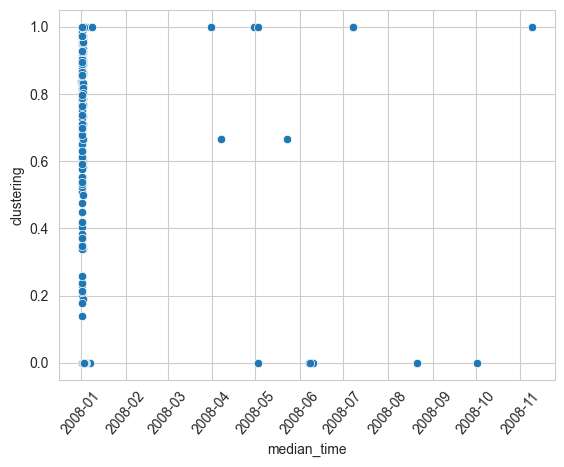

In [134]:
sns.scatterplot(data=resdf, x="median_time", y="clustering").tick_params(axis='x', labelrotation=50)

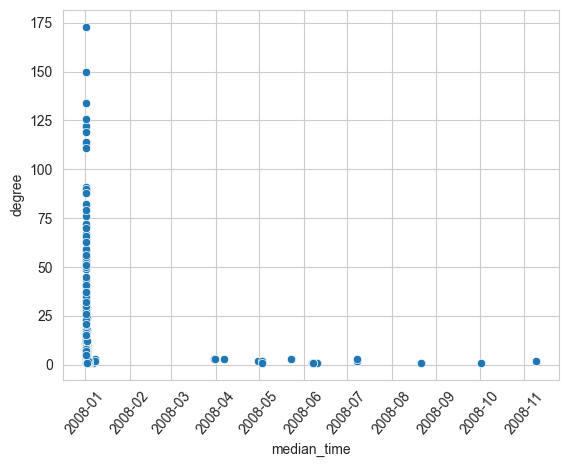

In [135]:
sns.scatterplot(data=resdf, x="median_time", y="degree").tick_params(axis='x', labelrotation=50)

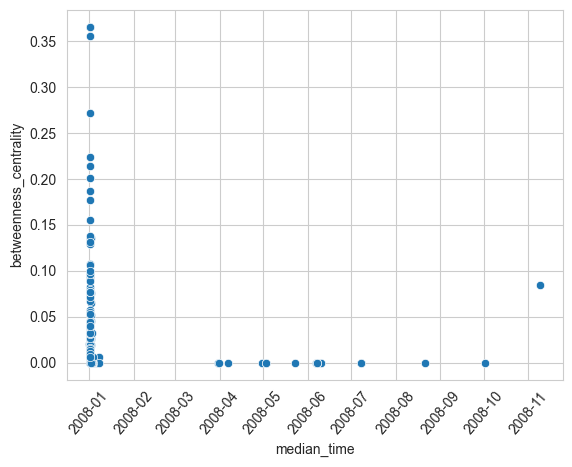

In [136]:
sns.scatterplot(data=resdf, x="median_time", y="betweenness_centrality").tick_params(axis='x', labelrotation=50)

In [137]:
from scipy import stats

fields = ['clustering', 'degree', 'betweenness_centrality']
for field in fields:
    spearman_corr, p_value = stats.spearmanr(resdf['median_time'].apply(lambda x: x.value), resdf[field])
    print(f"avg_time - {field}:\n\nSpearman Correlation:   {spearman_corr}\n             P_value:   {p_value}\n\n")

avg_time - clustering:

Spearman Correlation:   -0.05077546838867337
             P_value:   0.3784486210246165


avg_time - degree:

Spearman Correlation:   -0.7615575345543282
             P_value:   1.2113427472014404e-58


avg_time - betweenness_centrality:

Spearman Correlation:   -0.5257420185795914
             P_value:   6.193833843611118e-23




С временем заражения сильнее всего скоррелирована степень узла. Чем больше степень, тем меньше время заражения. Это можно объяснить тем, что чем больше маршрутов с другими аэропортами, тем чаще прилетают зараженные самолеты, тем быстрее аэропорт заражается. 

Степень посредничества менее коррелирует с временем заражения, но зависимость имеет место быть. Чем степень посредничества выше, тем вес смежных ребер должен быть меньше, тем меньше полетов через через данное ребро